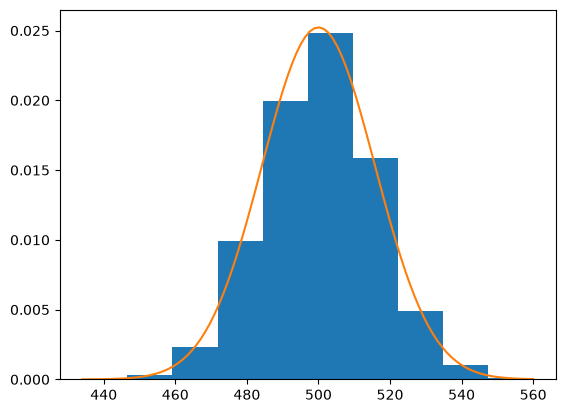

In [15]:
# chcemy sprawdzic czy rzut moneta jest sprawiedliwy
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import random
def bernoulli_trial(p):
    return 1 if p >= random.uniform(0,1) else 0

def bernoulli_realization(n,p):
    return np.sum([bernoulli_trial(p) for _ in range(n)]).item()

def normal_approximation_to_binomial(n,p):
    mu = n*p
    q = 1 - p
    sigma = (n * p * q)** 0.5
    return mu, sigma

n = 1000
p = 0.5
B = [bernoulli_realization(n,p) for _ in range(10_000)]

a_x = np.linspace(min(B), max(B), 100)
a_y = scipy.stats.norm.pdf(a_x, normal_approximation_to_binomial(n,p)[0], normal_approximation_to_binomial(n,p)[1])
plt.hist(B, density=True)
plt.plot(a_x, a_y)
plt.show()

In [ ]:
# tworzymy przedzial ufnosci, jezeli z sumuacji 1000 rzutow liczba orlow wpadnie w ten przedzial to na 95% kostka jest sprawiedliwa p = 0.5  
beta = scipy.stats.norm.ppf(1.95/2)
alpha = scipy.stats.norm.ppf(0.05/2)
left_bound = alpha * (n * p * (1 - p)) ** 0.5 + n*p
right_bound = beta * ( n * p * (1 - p))** 0.5 + n*p
left_bound, right_bound

(np.float64(469.0102483847719), np.float64(530.9897516152281))

In [ ]:
if  left_bound < bernoulli_realization(1000,p=1/2) < right_bound:
    print('nie ma podstaw do odrzucenia h0')
else:
    print('odrzucamy H0')

mna 95% sprawiedliwa


In [28]:
# sprwadznie mocy testu (blad beta)
p1 = 0.55
q1 = 1 - p1 
mu_1 = n * p1
sigma_1 = (p1*n*q1)**0.5

a = (left_bound - mu_1 )/ sigma_1 
b = (right_bound - mu_1 )/ sigma_1

beta_err = scipy.stats.norm.cdf(b) - scipy.stats.norm.cdf(a)

round(beta_err, 2), 1 - beta_err

(np.float64(0.11), np.float64(0.8865477810983827))

In [ ]:
# test A/B

def estimate_parameters(N, n):
    p = n / N
    sigma = (p * (1 - p) / N)**0.5
    return p, sigma

def p_val_test_ab(Na, na, Nb, nb):
    
    p_a, sigma_a = estimate_parameters(Na, na)
    p_b, sigma_b = estimate_parameters(Nb, nb) 
    
    sigma_diff = (sigma_a**2 + sigma_b**2)**0.5
    x = p_a - p_b
    z = x / sigma_diff
    
    q = scipy.stats.norm.cdf(np.abs(z)) 
    return 2 * (1 - q)

print(p_val_test_ab(1000, 200, 1000, 150))

0.003189699706216853


In [ ]:
import numpy as np
from scipy.stats import beta

# Parametry a posteriori dla Wersji A
alpha_A = 41
beta_A = 961

# Parametry a posteriori dla Wersji B
alpha_B = 61
beta_B = 941

symulacje_A = np.random.beta(alpha_A, beta_A, size=100000)
symulacje_B = np.random.beta(alpha_B, beta_B, size=100000)

wygrane_B = np.sum(symulacje_B > symulacje_A)
prawdopodobienstwo_B_lepsze = wygrane_B / 100000

print(f"Prawdopodobieństwo, że Wersja B jest lepsza od A: {prawdopodobienstwo_B_lepsze * 100:.2f}%")

print(f"Spodziewany Open Rate A: {(alpha_A / (alpha_A + beta_A)) * 100:.2f}%")
print(f"Spodziewany Open Rate B: {(alpha_B / (alpha_B + beta_B)) * 100:.2f}%")

Prawdopodobieństwo, że Wersja B jest lepsza od A: 97.96%
Spodziewany Open Rate A: 4.09%
Spodziewany Open Rate B: 6.09%
